In [1]:
import pandas as pd

doc = pd.read_csv('social-media-release.csv')
values = doc.value_counts("class_label")

print(values)
print("\nRatio of class labels:\nFalse: " + str(int((values[0]/(values[0]+values[1]))*100)) + "%\nTrue: " +str(int((values[1]/(values[0]+values[1]))*100)) + "%")

class_label
False    51879
True     37859
Name: count, dtype: int64

Ratio of class labels:
False: 57%
True: 42%


C:\Users\azeem\AppData\Local\Temp\ipykernel_9552\3582651123.py:7: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print("\nRatio of class labels:\nFalse: " + str(int((values[0]/(values[0]+values[1]))*100)) + "%\nTrue: " +str(int((values[1]/(values[0]+values[1]))*100)) + "%")


In [2]:
#deciding how long to make inputs to the neural network
posts_length = doc["post"].str.len()
print ("The maximum column length is:", max(posts_length))
print ("The mean column length is:", int(posts_length.mean()))
print ("The median column length is:", int(posts_length.median()))
print ("The standard deviation of column length is:", int(posts_length.std()))
print ("Using median + standard deviation, we will truncate posts at:", int(posts_length.std())+int(posts_length.median()), "characters.")

#seeing if there are any rows we must remove before beginning
print ("Missing values:", posts_length.isnull().sum())

#dropping row with null value
doc = doc.dropna()

The maximum column length is: 993.0
The mean column length is: 231
The median column length is: 250
The standard deviation of column length is: 84
Using median + standard deviation, we will truncate posts at: 334 characters.
Missing values: 1


Amount of posts in dataset: 89737
Amount of posts after removing rare headlines: 89663

 class_label
False    51863
True     37800
Name: count, dtype: int64

Ratio of class labels:
False: 57%
True: 42%


C:\Users\azeem\AppData\Local\Temp\ipykernel_9552\3834131719.py:11: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print("\nRatio of class labels:\nFalse: " + str(int((values[0]/(values[0]+values[1]))*100)) + "%\nTrue: " +str(int((values[1]/(values[0]+values[1]))*100)) + "%")


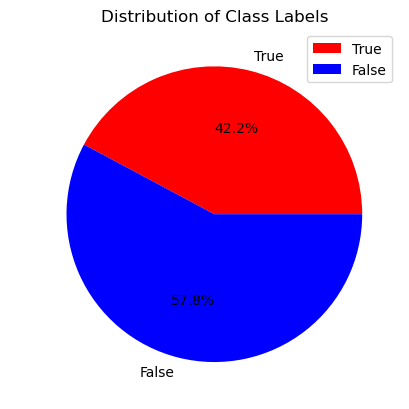

In [3]:
split = pd.DataFrame({'class': ['True', 'False'], ' ': [37859, 51879]})
split.set_index('class').plot.pie(y=' ', autopct='%1.1f%%', colors=['red', 'blue'], title='Distribution of Class Labels')   
print("Amount of posts in dataset:", doc.shape[0])
#remove infrequent headlines to prevent network 'memorising' specific posts instead of general characteristics
headline_counts = doc.value_counts("news_headline")
doc = doc[doc['news_headline'].isin(headline_counts[headline_counts > 1].index)]
print("Amount of posts after removing rare headlines:", doc.shape[0])
values = doc.value_counts("class_label")

print("\n", values)
print("\nRatio of class labels:\nFalse: " + str(int((values[0]/(values[0]+values[1]))*100)) + "%\nTrue: " +str(int((values[1]/(values[0]+values[1]))*100)) + "%")

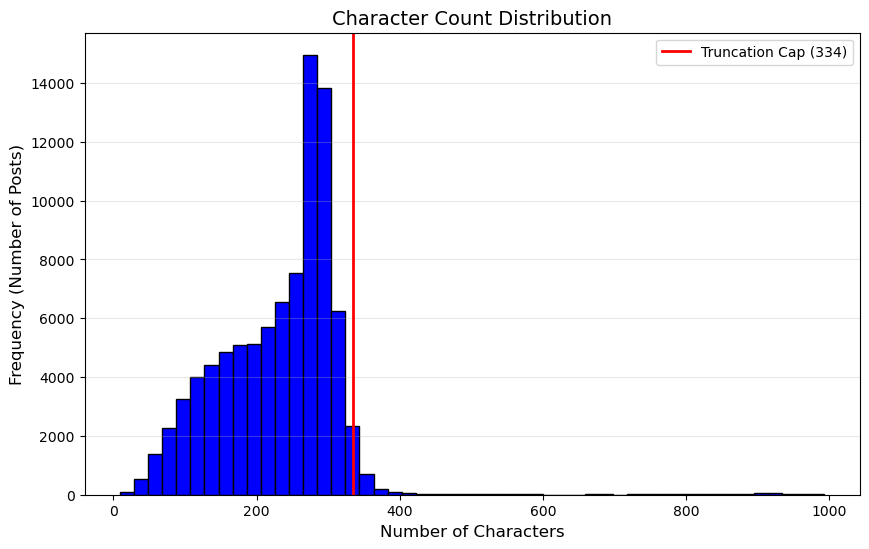

In [4]:
import matplotlib.pyplot as plt

#histogram to show character count distribution in the posts
plt.figure(figsize=(10, 6))
plt.hist(posts_length, bins=50, color='blue', edgecolor='black')

#truncating line and labels
plt.axvline(334, color='red', linewidth=2, label='Truncation Cap (334)')
plt.title('Character Count Distribution', fontsize=14)
plt.xlabel('Number of Characters', fontsize=12)
plt.ylabel('Frequency (Number of Posts)', fontsize=12)
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.show()

In [5]:
import spacy
nlp = spacy.load("en_core_web_sm")

#work on a copy to avoid modifying the original
df = doc.copy() 

def preprocess_social_media_posts(texts):
    #performs tokenisation, lemmatisation and stop word removal
    cleaned_docs = []
    
    #disabled the parser and NER to speed up the process since they aren't needed for BoW/TF-IDF
    for spacy_doc in nlp.pipe(texts, disable=['parser', 'ner'], batch_size=1000):
        #extract the lemma for each token, lowercase it, and filter out stop words and punctuation
        tokens = [
            token.lemma_.lower() 
            for token in spacy_doc 
            if not token.is_stop and not token.is_punct and not token.is_space
        ]
        #rejoin tokens into a cleaned string for vectorization
        cleaned_docs.append(" ".join(tokens))
        
    return cleaned_docs

#applying the preprocessing to truncated posts
df['cleaned_post'] = preprocess_social_media_posts(df['post'].str[:334].astype(str))
df.to_csv('preprocessed.csv', index=False)  # save
print(f"Loaded {len(df)} documents")

#visual verification of the syntactic analysis
print("Preprocessing Results")
print("Original Post Sample:", df['post'].iloc[0])
print("Processed Tokens Sample:", df['cleaned_post'].iloc[0])
print(f"\nTotal processed documents: {len(df['cleaned_post'])}")

Preprocessing Results
Original Post Sample: @POTUS Biden Blunders - 6 Month Update

Inflation, Delta mismanagement, COVID for kids, Abandoning Americans in Afghanistan, Arming the Taliban, S. Border crisis, Breaking job growth, Abuse of power (Many Exec Orders, $3.5T through Reconciliation, Eviction Moratorium)...what did I miss?
Processed Tokens Sample: @potus biden blunders 6 month update inflation delta mismanagement covid kid abandon americans afghanistan arm taliban s. border crisis break job growth abuse power exec orders $ 3.5 t reconciliation eviction moratorium) miss

Total processed documents: 89663


In [6]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split

y = df['class_label']
X = df['cleaned_post']

#split train-val:test 80:20
X_train_val, X_test_raw, y_train_val, y_test = train_test_split(
    X, y, test_size=0.20, random_state=1, shuffle=True
)

#splitting test-validation again, 75:25 makes 60% and 20% of overall dataset here
X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, random_state=1, shuffle=True
)

vectorizer = CountVectorizer(min_df=5) 
X_train = vectorizer.fit_transform(X_train_raw)
X_val = vectorizer.transform(X_val_raw)
X_test = vectorizer.transform(X_test_raw)

print(f"The Vocabulary includes {X_train.shape[1]} unique words.")
print(f"Training set: {X_train.shape[0]} samples (60%)")
print(f"Validation set: {X_val.shape[0]} samples (20%)")
print(f"Test set: {X_test.shape[0]} samples (20%)")

feature_names = vectorizer.get_feature_names_out()
print(f"\nSample Features: {feature_names[5000:5020]}")

The Vocabulary includes 11728 unique words.
Training set: 53797 samples (60%)
Validation set: 17933 samples (20%)
Test set: 17933 samples (20%)

Sample Features: ['highways' 'highwiretalk' 'hijack' 'hike' 'hilarious' 'hilary' 'hill'
 'hillary' 'hillaryclinton' 'hillarys' 'hillbeverlyhill' 'hillbilly' 'him'
 'hinder' 'hindu' 'hint' 'hipaa' 'hippa' 'hire' 'his']


In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer

#tf-idf
tfidf_vect = TfidfVectorizer(min_df=5)
X_tfidf_train = tfidf_vect.fit_transform(X_train_raw)
X_tfidf_val   = tfidf_vect.transform(X_val_raw)
X_tfidf_test  = tfidf_vect.transform(X_test_raw)

#tf-idf + bigrams
#initialize the tf-idf vectoriser with n-grams
tfidf_ngram_vect = TfidfVectorizer(min_df=5, ngram_range=(1, 2))
X_tfidf_ngram_train = tfidf_ngram_vect.fit_transform(X_train_raw)
X_tfidf_ngram_val   = tfidf_ngram_vect.transform(X_val_raw)
X_tfidf_ngram_test  = tfidf_ngram_vect.transform(X_test_raw)

#verification
print(f"Feature Matrix Shape (Unigrams + Bigrams): {X_tfidf_ngram_train.shape}")

# inspect the vocabulary to see the bigrams
feature_names = tfidf_vect.get_feature_names_out()
#slicing later in the list to avoid the initial numeric noise
print(f"\nSample n-gram features: {feature_names[10000:10015]}")

Feature Matrix Shape (Unigrams + Bigrams): (53797, 36118)

Sample n-gram features: ['stair' 'stake' 'stall' 'stamp' 'stamps' 'stan' 'stance' 'stand'
 'standamericanow' 'standard' 'standing' 'standpoint' 'stanford' 'star'
 'starbucks']


In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

for name, X_tr, X_te in [
    ("BoW", X_train, X_test),
    ("TF-IDF", X_tfidf_train, X_tfidf_test),
    ("TF-IDF+Bigrams", X_tfidf_ngram_train, X_tfidf_ngram_test)
]:
    clf = LogisticRegression(max_iter=1000)
    clf.fit(X_tr, y_train)
    print(f"\n--- {name} ---")
    print(classification_report(y_test, clf.predict(X_te)))


--- BoW ---
              precision    recall  f1-score   support

       False       0.92      0.94      0.93     10272
        True       0.92      0.89      0.91      7661

    accuracy                           0.92     17933
   macro avg       0.92      0.92      0.92     17933
weighted avg       0.92      0.92      0.92     17933


--- TF-IDF ---
              precision    recall  f1-score   support

       False       0.93      0.94      0.94     10272
        True       0.92      0.90      0.91      7661

    accuracy                           0.93     17933
   macro avg       0.93      0.92      0.92     17933
weighted avg       0.93      0.93      0.93     17933


--- TF-IDF+Bigrams ---
              precision    recall  f1-score   support

       False       0.93      0.95      0.94     10272
        True       0.93      0.91      0.92      7661

    accuracy                           0.93     17933
   macro avg       0.93      0.93      0.93     17933
weighted avg       0.

In [10]:
import pickle

with open('tfidf_vect.pkl', 'wb') as f:
    pickle.dump(tfidf_vect, f)
with open('splits.pkl', 'wb') as f:
    pickle.dump({
        'X_train': X_tfidf_train,
        'X_val':   X_tfidf_val,
        'X_test':  X_tfidf_test,
        'y_train': y_train,
        'y_val':   y_val,
        'y_test':  y_test
    }, f)

print("Saved: tfidf_vect.pkl, splits.pkl")

Saved: tfidf_vect.pkl, splits.pkl
